# The history estimators of adaptive data rate, as baselines

The history inputs of notebooks 12 to 16 are not new as an idea: adaptive data rate schemes already estimate a link from its recent packets, and the literature offers several estimators, a moving average, a median, a Gaussian filter (the mean of the last packets within one standard deviation of their mean), an exponential average, a Kalman filter, a linear regression over the last packets, and the standard rule that uses the best of the last 20 packets. This notebook puts them on the same footing as the ML models.

* An operating link transmits at one spreading factor, and the ADR of The Things Stack uses only the uplinks at the current data rate. Every estimator therefore predicts the current path loss from the earlier packets of the same link at the spreading factor of the predicted packet. A time window that holds no such packet falls back to the mean of the last 60, then of the last 20 packets at that spreading factor, as the anchor does.
* Here the spreading factor changes every five uplinks, so 20 packets at one spreading factor span about four times as long as on a link that stays at one. Two more versions bound this: all earlier packets of the link with a running offset per spreading factor removed (the mean deviation from the anchor over the link's previous 500 packets at that factor), which keeps the window recent; and all earlier packets as they are, which mixes the spreading factors.
* The margin above the anchor is `p - a + c`, with the prediction `p` and the shift `c` calibrated on the validation folds exactly as in notebook 16. Two calibrations: one shift per group (spreading factor x working hours), which needs no feedback, and adaptive conformal inference per link, which uses the observed misses.
* The exponential average and the Kalman filter are tuned on the validation folds only, in each version. All scores are on the hold-out, with 95 % intervals from resampling days.
* The ML model is the LightGBM on rung H4, read from its saved predictions.
* The standard rule without calibration: the best of the last 20 packets plus a fixed 10 dB, overall, by spreading factor and by link.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from history_features import RUNGS
from margin_tools import pinball, shift_pooled, shift_groups, aci, day_codes, boot_stat, transitions, clustering_ratio

TAU = 0.99

In [2]:
# The rows and folds of notebooks 13 to 16
train = pd.read_csv("Data_Files/history_train.csv")
test = pd.read_csv("Data_Files/history_test.csv")
d = pd.concat([train, test], ignore_index=True)
d["t"] = pd.to_datetime(d["t"], utc=True)
d = d.sort_values("t").reset_index(drop=True)
fold = d["fold"].to_numpy()
H = {k.split()[0]: v for k, v in RUNGS.items()}
ok = (d["y"].notna() & d[H["H7"]].notna().all(axis=1)).to_numpy()
PL, a, y = d["PL"].to_numpy(), d["a"].to_numpy(), d["y"].to_numpy()
link, sf, work = d["device_id"].to_numpy(), d["SF"].to_numpy().astype(int), d["work"].to_numpy().astype(int)
day = day_codes(d["t"])
val, ev = ok & (fold >= 0) & (fold < 9), ok & (fold == 9)
print(f"packets {len(d):,}; duplicated (link, time) pairs: {d.duplicated(['device_id', 't']).sum()}; validation {val.sum():,}; hold-out {ev.sum():,}")

packets 2,660,274; duplicated (link, time) pairs: 0; validation 1,773,285; hold-out 531,983


In [3]:
# Estimators of the current path loss from earlier packets of the link
def gaussian_filter(w):
    """Mean of the window's values within one standard deviation of their mean (the Gaussian filter of G-ADR); at least one value always qualifies."""
    w = w[np.isfinite(w)]
    return w[np.abs(w - w.mean()) <= w.std(ddof=1)].mean()

def linear_extrapolation(s, n=20):
    """Least-squares line through the last n packets, extended by one step (the linear-regression scheme)."""
    v = s.to_numpy()
    mean = s.shift(1).rolling(n, min_periods=n).mean().to_numpy()
    weighted = np.convolve(v, np.arange(n + 1))[: len(v)]               # sum over k of k * v[t - k]
    slope = (-weighted + n * (n + 1) / 2 * mean) / (n * (n * n - 1) / 12)
    return pd.Series(mean + slope * (n + 1) / 2, index=s.index)

def kalman(pl, minutes, q, r=1.0):
    """Kalman filter for a drifting level: the level moves by a random step whose variance grows with the minutes since the last packet."""
    pred = np.full(len(pl), np.nan)
    x, p = pl[0], r
    for i in range(1, len(pl)):
        p += q * minutes[i]
        pred[i] = x
        gain = p / (p + r)
        x += gain * (pl[i] - x)
        p *= 1 - gain
    return pred

rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))

def estimators(keys, v):
    """Every estimator of the series v from its earlier values in the same group (keys: the link, or the link and the SF). A time window that holds
    no earlier value falls back to the mean of the last 60, then of the last 20 values, as the anchor does. The exponential average and the Kalman
    filter are tuned on the validation folds. Returns the estimates and the validation RMSE of every candidate setting."""
    frame = d[keys].assign(v=v, t=d["t"])
    g = frame.groupby(keys, sort=False)["v"]
    last = lambda n, how="mean": g.transform(lambda s: getattr(s.shift(1).rolling(n, min_periods=n // 2), how)()).to_numpy()
    est = {"previous packet": g.shift(1).to_numpy(), "mean of the last 20": last(20), "median of the last 20": last(20, "median"),
           "Gaussian filter of the last 20": g.transform(lambda s: s.shift(1).rolling(20, min_periods=10).apply(gaussian_filter, raw=True)).to_numpy(),
           "best of the last 20": last(20, "min")}                          # lowest path loss = highest SNR, the standard rule
    last60 = last(60)
    fallback = np.where(np.isnan(last60), est["mean of the last 20"], last60)
    for name, span in (("previous hour mean", "1h"), ("24 hour mean", "24h")):
        m = np.full(len(d), np.nan)
        for _, x in frame.groupby(keys, sort=False):
            m[x.index] = x.set_index("t")["v"].rolling(span, closed="left").mean().to_numpy()
        est[name] = np.where(np.isnan(m), fallback, m)
    est["linear regression over the last 20"] = g.transform(linear_extrapolation).to_numpy()
    ema = {w: g.transform(lambda s: s.shift(1).ewm(alpha=w, adjust=False).mean()).to_numpy() for w in (0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5)}
    minutes = frame.groupby(keys, sort=False)["t"].diff().dt.total_seconds().to_numpy() / 60
    code = frame.groupby(keys, sort=False).ngroup().to_numpy()
    kal = {}
    for q in (1e-4, 1e-3, 1e-2, 1e-1):
        kal[q] = np.full(len(d), np.nan)
        for c in np.unique(code):
            i = np.flatnonzero(code == c)
            kal[q][i] = kalman(v[i], minutes[i], q)
    ema_score = {w: rmse((v - p)[val & np.isfinite(p)]) for w, p in ema.items()}
    kal_score = {q: rmse((v - p)[val & np.isfinite(p)]) for q, p in kal.items()}
    w, q = min(ema_score, key=ema_score.get), min(kal_score, key=kal_score.get)
    est["exponential average"], est["Kalman filter"] = ema[w], kal[q]
    tuning = pd.DataFrame([dict(estimator="exponential average", setting="weight", value=k, validation_rmse=s, selected=k == w) for k, s in ema_score.items()]
                          + [dict(estimator="Kalman filter", setting="drift variance per minute", value=k, validation_rmse=s, selected=k == q) for k, s in kal_score.items()])
    tuning["median interval s"] = float(np.nanmedian(minutes) * 60)
    return est, tuning

In [4]:
# Three versions: the link's earlier packets at the SF of the predicted packet (the figure); all its earlier packets with a running offset per SF
# removed, the mean deviation from the anchor over the link's previous 500 packets at that SF (at least 50; none before); all its earlier packets as they are
offset = d.groupby(["device_id", "SF"], sort=False)["y"].transform(lambda s: s.shift(1).rolling(500, min_periods=50).mean()).fillna(0.0).to_numpy()
VERSIONS = {"same SF": (["device_id", "SF"], np.zeros(len(d))), "all SFs, SF offset removed": (["device_id"], offset), "all SFs": (["device_id"], np.zeros(len(d)))}
est, tuning = {}, []
for version, (keys, off) in VERSIONS.items():
    t0 = time.time()
    e, tu = estimators(keys, PL - off)
    est[version] = {name: p + off for name, p in e.items()}
    tuning.append(tu.assign(version=version))
    print(f"{version}: {time.time() - t0:.0f} s; selected on the validation folds: "
          + "; ".join(f"{r.estimator}, {r.setting} {r.value:g} (RMSE {r.validation_rmse:.3f} dB)" for r in tu[tu.selected].itertuples()))
tuning = pd.concat(tuning)[["version", "estimator", "setting", "value", "validation_rmse", "selected", "median interval s"]]
tuning.to_csv("CV_Results/adr_estimator_tuning.csv", index=False)
print("validation RMSE of every candidate setting (dB)")
display(tuning.pivot_table(index=["estimator", "value"], columns="version", values="validation_rmse")[list(VERSIONS)].round(3))

same SF: 40 s; selected on the validation folds: exponential average, weight 0.2 (RMSE 3.039 dB); Kalman filter, drift variance per minute 0.01 (RMSE 3.047 dB)


all SFs, SF offset removed: 39 s; selected on the validation folds: exponential average, weight 0.05 (RMSE 3.020 dB); Kalman filter, drift variance per minute 0.01 (RMSE 3.024 dB)


all SFs: 40 s; selected on the validation folds: exponential average, weight 0.05 (RMSE 3.245 dB); Kalman filter, drift variance per minute 0.01 (RMSE 3.249 dB)
validation RMSE of every candidate setting (dB)


version                     same SF  all SFs, SF offset removed  all SFs
estimator           value                                               
Kalman filter       0.0001    3.290                       3.142    3.356
                    0.0010    3.086                       3.034    3.257
                    0.0100    3.047                       3.024    3.249
                    0.1000    3.300                       3.138    3.332
exponential average 0.0050    3.742                       3.275    3.482
                    0.0100    3.525                       3.155    3.369
                    0.0200    3.351                       3.073    3.292
                    0.0500    3.166                       3.020    3.245
                    0.1000    3.064                       3.022    3.248
                    0.2000    3.039                       3.071    3.283
                    0.5000    3.287                       3.332    3.480

In [5]:
# The ML model, LightGBM on rung H4, from its saved predictions (validation folds out of fold, hold-out from the final fit), the same in every version
position = pd.Series(np.arange(len(d)), index=pd.MultiIndex.from_arrays([d["device_id"], d["t"]]))
def saved(model):
    p = np.full(len(d), np.nan)
    for split in ("oof", "test"):
        r = pd.read_csv(f"Residuals/residuals_{model}_{split}.csv", usecols=["time", "device_id", "PL_pred"])
        i = position.reindex(pd.MultiIndex.from_arrays([r["device_id"], pd.to_datetime(r["time"], utc=True)])).to_numpy()
        found = ~np.isnan(i)
        p[i[found].astype(int)] = r["PL_pred"].to_numpy()[found]
    return p
reference = "LightGBM on rung H4"
lightgbm_pred = saved("LGBM_H4")
for version in est:
    est[version][reference] = lightgbm_pred

common = ok & np.all([np.isfinite(p) for e in est.values() for p in e.values()], axis=0)
val_c, ev_c = val & common, ev & common
print(f"{len(est['same SF'])} estimators in each of {len(est)} versions; rows where every estimator is defined: validation {val_c.sum():,}, hold-out {ev_c.sum():,}")

11 estimators in each of 3 versions; rows where every estimator is defined: validation 1,773,285, hold-out 531,983


In [6]:
# Margins on the hold-out: the shift comes from the validation folds; coverage, margin above the anchor and pinball loss at 99 %, with 95 % intervals
# from resampling days, and the difference in pinball loss to LightGBM
te, cal = np.flatnonzero(ev_c), np.flatnonzero(val_c)
g1_cal, g1_te = (sf[cal] - 7) * 2 + work[cal], (sf[te] - 7) * 2 + work[te]
dd = pd.factorize(day[te])[0]
ci = lambda cols, f: boot_stat(dd, np.column_stack(cols), f)
rows = []
for version, e in est.items():
    margin = {}
    for name, p in e.items():
        b = p - a                                                    # threshold above the anchor before the shift
        score = PL[cal] - p[cal]
        margin[(name, "SF x hours")] = b[te] + shift_groups(score, g1_cal, g1_te, TAU)
        m = np.empty(len(te))
        for l in np.unique(link[te]):
            i = np.flatnonzero(link[te] == l)
            m[i] = aci(b[te][i], y[te][i], score, TAU, (1 - TAU) / 20)
        margin[(name, "ACI")] = m
    for (name, how), mm in margin.items():
        miss = (y[te] > mm).astype(float)
        loss = pinball(y[te], mm, TAU)
        ratio = clustering_ratio(transitions(d["t"].iloc[te], link[te], miss).sum(0, keepdims=True))[0]
        _, margin_lo, margin_hi = ci([mm, np.ones(len(te))], lambda T: T[:, 0] / T[:, 1])
        diff, lo, hi = ci([loss - pinball(y[te], margin[(reference, how)], TAU), np.ones(len(te))], lambda T: 1000 * T[:, 0] / T[:, 1])
        _, rmse_lo, rmse_hi = ci([np.square(PL[te] - e[name][te]), np.ones(len(te))], lambda T: np.sqrt(T[:, 0] / T[:, 1]))
        rows.append(dict(version=version, estimator=name, calibration=how, rmse=rmse(PL[te] - e[name][te]), coverage=1 - miss.mean(), margin=mm.mean(), margin_lo=margin_lo,
                         margin_hi=margin_hi, pinball=loss.mean() * 1000, miss_clustering=ratio, pinball_minus_lightgbm=diff, lo=lo, hi=hi, rmse_lo=rmse_lo, rmse_hi=rmse_hi))
result = pd.DataFrame(rows)
result.to_csv("CV_Results/adr_estimators.csv", index=False)
same = result[result.version == "same SF"]
order = same[same.calibration == "SF x hours"].sort_values("rmse").estimator.tolist()
print("hold-out, the link's earlier packets at the same SF, by estimator: RMSE of the level estimate and, per calibration, coverage, mean margin above the anchor "
      "with its 95 % interval, pinball loss x 1000 and its difference to LightGBM")
display(same.drop(columns="version").set_index(["estimator", "calibration"]).loc[[(n, c) for n in order for c in ("SF x hours", "ACI")]].round(3))
lgbm_margin = result[result.estimator == reference].set_index(["version", "calibration"]).margin
result["margin above LightGBM"] = result.margin.to_numpy() - lgbm_margin.reindex(pd.MultiIndex.from_frame(result[["version", "calibration"]])).to_numpy()
print("the three versions: RMSE (dB), coverage, and the mean margin above that of LightGBM (dB), per calibration")
display(result.pivot_table(index="estimator", columns="version", values="rmse").loc[order, list(VERSIONS)].round(3))
display(result.pivot_table(index="estimator", columns=["calibration", "version"], values="coverage").loc[order].round(4))
display(result.pivot_table(index="estimator", columns=["calibration", "version"], values="margin above LightGBM").loc[order].round(2))

hold-out, the link's earlier packets at the same SF, by estimator: RMSE of the level estimate and, per calibration, coverage, mean margin above the anchor with its 95 % interval, pinball loss x 1000 and its difference to LightGBM


rmse  coverage  margin  \
estimator                          calibration                            
LightGBM on rung H4                SF x hours   1.770     0.993   4.636   
                                   ACI          1.770     0.991   4.319   
Kalman filter                      SF x hours   2.104     0.993   5.309   
                                   ACI          2.104     0.991   5.155   
exponential average                SF x hours   2.111     0.993   5.361   
                                   ACI          2.111     0.991   5.175   
previous hour mean                 SF x hours   2.170     0.993   5.512   
                                   ACI          2.170     0.991   5.425   
mean of the last 20                SF x hours   2.189     0.993   5.795   
                                   ACI          2.189     0.991   5.584   
Gaussian filter of the last 20     SF x hours   2.235     0.993   6.056   
                                   ACI          2.235     0.991   5.879   
linear regression over the last 20 SF x hours   2.250     0.993   5.605   
                                   ACI          2.250     0.991   5.442   
median of the last 20              SF x hours   2.253     0.993   6.163   
                                   ACI          2.253     0.991   5.979   
previous packet                    SF x hours   2.741     0.992   6.444   
                                   ACI          2.741     0.991   6.664   
24 hour mean                       SF x hours   2.854     0.993   8.441   
                                   ACI          2.854     0.991   7.061   
best of the last 20                SF x hours   4.270     0.996   9.523   
                                   ACI          4.270     0.991   7.776   

                                                margin_lo  margin_hi  pinball  \
estimator                          calibration                                  
LightGBM on rung H4                SF x hours       4.542      4.725   61.364   
                                   ACI              4.189      4.473   63.083   
Kalman filter                      SF x hours       5.189      5.424   68.530   
                                   ACI              4.996      5.345   71.153   
exponential average                SF x hours       5.229      5.485   68.738   
                                   ACI              5.016      5.365   71.412   
previous hour mean                 SF x hours       5.364      5.654   71.976   
                                   ACI              5.248      5.626   75.110   
mean of the last 20                SF x hours       5.603      5.978   73.866   
                                   ACI              5.377      5.818   76.989   
Gaussian filter of the last 20     SF x hours       5.842      6.256   77.844   
                                   ACI              5.643      6.158   81.167   
linear regression over the last 20 SF x hours       5.470      5.734   71.084   
                                   ACI              5.292      5.619   73.864   
median of the last 20              SF x hours       5.954      6.362   78.140   
                                   ACI              5.746      6.258   81.615   
previous packet                    SF x hours       6.373      6.511   81.739   
                                   ACI              6.525      6.841   84.267   
24 hour mean                       SF x hours       8.181      8.696  108.587   
                                   ACI              6.766      7.405   92.895   
best of the last 20                SF x hours       9.334      9.704  109.639   
                                   ACI              7.502      8.092  101.128   

                                                miss_clustering  \
estimator                          calibration                    
LightGBM on rung H4                SF x hours            12.038   
                                   ACI                    9.890   
Kalman filter                      

the three versions: RMSE (dB), coverage, and the mean margin above that of LightGBM (dB), per calibration


version,same SF,"all SFs, SF offset removed",all SFs
estimator,,,
LightGBM on rung H4,1.770,1.770,1.770
Kalman filter,2.104,2.015,2.396
exponential average,2.111,2.038,2.410
previous hour mean,2.170,2.121,2.481
mean of the last 20,2.189,2.033,2.392
Gaussian filter of the last 20,2.235,2.054,2.422
linear regression over the last 20,2.250,2.157,2.740
median of the last 20,2.253,2.061,2.438
previous packet,2.741,2.774,2.962


calibration                            ACI                                     \
version                            all SFs all SFs, SF offset removed same SF   
estimator                                                                       
LightGBM on rung H4                 0.9905                     0.9905  0.9905   
Kalman filter                       0.9905                     0.9907  0.9906   
exponential average                 0.9904                     0.9907  0.9906   
previous hour mean                  0.9904                     0.9906  0.9906   
mean of the last 20                 0.9905                     0.9907  0.9906   
Gaussian filter of the last 20      0.9905                     0.9908  0.9907   
linear regression over the last 20  0.9905                     0.9908  0.9906   
median of the last 20               0.9905                     0.9908  0.9907   
previous packet                     0.9906                     0.9907  0.9907   
24 hour mean                        0.9907                     0.9909  0.9909   
best of the last 20                 0.9906                     0.9910  0.9908   

calibration                        SF x hours                             \
version                               all SFs all SFs, SF offset removed   
estimator                                                                  
LightGBM on rung H4                    0.9933                     0.9933   
Kalman filter                          0.9936                     0.9934   
exponential average                    0.9937                     0.9934   
previous hour mean                     0.9931                     0.9929   
mean of the last 20                    0.9944                     0.9939   
Gaussian filter of the last 20         0.9950                     0.9944   
linear regression over the last 20     0.9929                     0.9948   
median of the last 20                  0.9950                     0.9945   
previous packet                        0.9920                     0.9932   
24 hour mean                           0.9932                     0.9932   
best of the last 20                    0.9972                     0.9977   

calibration                                 
version                            same SF  
estimator                                   
LightGBM on rung H4                 0.9933  
Kalman filter                       0.9931  
exponential average                 0.9931  
previous hour mean                  0.9929  
mean of the last 20                 0.9934  
Gaussian filter of the last 20      0.9935  
linear regression over the last 20  0.9931  
median of the last 20               0.9934  
previous packet                     0.9915  
24 hour mean                        0.9931  
best of the last 20                 0.9960

calibration                            ACI                                     \
version                            all SFs all SFs, SF offset removed same SF   
estimator                                                                       
LightGBM on rung H4                   0.00                       0.00    0.00   
Kalman filter                         1.80                       0.51    0.84   
exponential average                   1.94                       0.68    0.86   
previous hour mean                    2.24                       1.01    1.11   
mean of the last 20                   1.93                       0.60    1.26   
Gaussian filter of the last 20        2.02                       0.74    1.56   
linear regression over the last 20    2.23                       0.77    1.12   
median of the last 20                 2.09                       0.78    1.66   
previous packet                       2.63                       2.21    2.34   
24 hour mean                          3.57                       2.68    2.74   
best of the last 20                   3.52                       2.55    3.46   

calibration                        SF x hours                             \
version                               all SFs all SFs, SF offset removed   
estimator                                                                  
LightGBM on rung H4                      0.00                       0.00   
Kalman filter                            0.59                       0.45   
exponential average                      0.69                       0.59   
previous hour mean                       0.88                       0.80   
mean of the last 20                      0.76                       0.59   
Gaussian filter of the last 20           0.93                       0.83   
linear regression over the last 20       1.09                       0.91   
median of the last 20                    1.13                       0.90   
previous packet                          2.08                       1.93   
24 hour mean                             3.88                       3.76   
best of the last 20                      4.77                       5.44   

calibration                                 
version                            same SF  
estimator                                   
LightGBM on rung H4                   0.00  
Kalman filter                         0.67  
exponential average                   0.72  
previous hour mean                    0.88  
mean of the last 20                   1.16  
Gaussian filter of the last 20        1.42  
linear regression over the last 20    0.97  
median of the last 20                 1.53  
previous packet                       1.81  
24 hour mean                          3.80  
best of the last 20                   4.89

In [7]:
# The standard rule without calibration, in each version: the best of the last 20 packets plus a fixed 10 dB, overall (with the 95 % interval
# of the coverage from resampling days), by SF and by link; and the same 10 dB above the mean of the last 20 packets
fixed = 10.0
by_sf = [s for s in np.unique(sf[te]) if (sf[te] == s).sum() >= 1000]
rows = []
for version, e in est.items():
    for name in ("best of the last 20", "mean of the last 20"):
        rule = (e[name] - a)[te] + fixed
        hit = (y[te] <= rule).astype(float)
        cover, lo, hi = ci([hit, np.ones(len(te))], lambda T: T[:, 0] / T[:, 1])
        rows.append(dict(version=version, rule=f"{name} plus {fixed:.0f} dB", coverage=cover, coverage_lo=lo, coverage_hi=hi, margin=rule.mean(),
                         pinball=pinball(y[te], rule, TAU).mean() * 1000, **{f"coverage SF{s}": hit[sf[te] == s].mean() for s in by_sf},
                         **{f"coverage {l}": hit[link[te] == l].mean() for l in np.unique(link[te])}))
rules = pd.DataFrame(rows)
rules.to_csv("CV_Results/adr_reference_rule.csv", index=False)
print(f"target {TAU}: coverage, mean margin above the anchor (dB), pinball loss x 1000, and the coverage by SF and by link")
display(rules.set_index(["version", "rule"]).T.round(4))

target 0.99: coverage, mean margin above the anchor (dB), pinball loss x 1000, and the coverage by SF and by link


version                              same SF                                 \
rule          best of the last 20 plus 10 dB mean of the last 20 plus 10 dB   
coverage                              0.9832                         0.9983   
coverage_lo                           0.9805                         0.9979   
coverage_hi                           0.9858                         0.9988   
margin                                6.6142                        10.0010   
pinball                             117.0806                       108.7832   
coverage SF7                          0.9874                         0.9983   
coverage SF8                          0.9870                         0.9985   
coverage SF9                          0.9723                         0.9982   
coverage SF10                         0.9861                         0.9983   
coverage ED0                          0.9873                         0.9979   
coverage ED1                          0.9918                         0.9985   
coverage ED2                          0.9696                         0.9966   
coverage ED3                          0.9929                         0.9999   
coverage ED4                          0.9847                         0.9981   
coverage ED5                          0.9731                         0.9990   

version           all SFs, SF offset removed                                 \
rule          best of the last 20 plus 10 dB mean of the last 20 plus 10 dB   
coverage                              0.9875                         0.9990   
coverage_lo                           0.9857                         0.9987   
coverage_hi                           0.9893                         0.9993   
margin                                6.4602                        10.0000   
pinball                              99.9084                       106.5174   
coverage SF7                          0.9892                         0.9991   
coverage SF8                          0.9889                         0.9990   
coverage SF9                          0.9827                         0.9988   
coverage SF10                         0.9892                         0.9990   
coverage ED0                          0.9917                         0.9988   
coverage ED1                          0.9939                         0.9990   
coverage ED2                          0.9770                         0.9977   
coverage ED3                          0.9921                         0.9999   
coverage ED4                          0.9907                         0.9991   
coverage ED5                          0.9798                         0.9995   

version                              all SFs                                 
rule          best of the last 20 plus 10 dB mean of the last 20 plus 10 dB  
coverage                              0.9772                         0.9989  
coverage_lo                           0.9751                         0.9986  
coverage_hi                           0.9792                         0.9991  
margin                                6.1929                        10.0000  
pinball                             113.3022                       106.8927  
coverage SF7                          0.9874                         0.9991  
coverage SF8                          0.9897                         0.9991  
coverage SF9                          0.9377                         0.9980  
coverage SF10                         0.9936                         0.9993  
coverage ED0                          0.9799                         0.9988  
coverage ED1                          0.9855                         0.9990  
coverage ED2                          0.9613                         0.9975  
coverage ED3                          0.9847                         0.9998  
coverage ED4                          0.9821                         0.9990  
coverage ED5                          0.9696                    

In [8]:
# The measured path loss by spreading factor: mean deviation from the previous-hour mean on the training window, per link
train_rows = (fold < 9) & np.isfinite(y)
offsets = pd.DataFrame({"SF": sf[train_rows], "link": link[train_rows], "y": y[train_rows]}).groupby(["SF", "link"])["y"].mean().unstack()
offsets["min over links"], offsets["max over links"] = offsets.min(axis=1), offsets.max(axis=1)
offsets.to_csv("CV_Results/sf_offsets.csv")
display(offsets.round(2))

link,ED0,ED1,ED2,ED3,ED4,ED5,min over links,max over links
SF,,,,,,,,
7,-0.06,-0.32,0.20,0.49,-0.01,0.12,-0.32,0.49
8,-0.20,-0.52,-0.31,-0.47,-0.27,-0.31,-0.52,-0.20
9,1.98,2.26,1.95,1.85,1.98,1.83,1.83,2.26
10,-1.54,-1.37,-1.68,-1.77,-1.52,-1.34,-1.77,-1.34
11,-0.90,-0.82,-1.05,-1.05,-0.93,-0.92,-1.05,-0.82
12,0.56,0.70,0.71,0.77,0.57,0.48,0.48,0.77


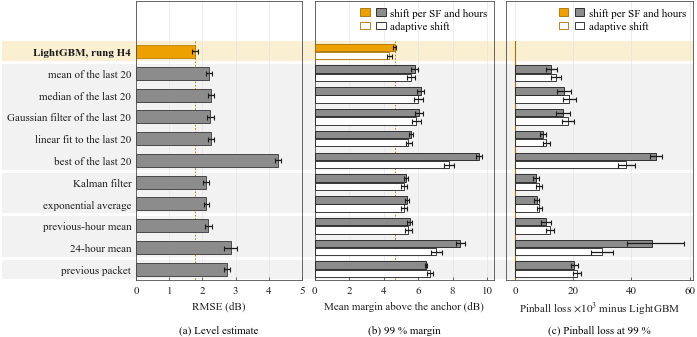

In [9]:
# Figure: the estimators on the link's earlier packets at the same SF against LightGBM on rung H4 as bars, hold-out, 99 % target; one shaded region
# per kind of estimator with a white gap between kinds, running behind the labels and the three panels; the whiskers are the 95 % intervals; (b) and (c)
# carry the calibration key, one entry per line, in a strip above the first row, and the cell checks that the key clears the row
import paper_figures as pf
from matplotlib.legend_handler import HandlerTuple
from matplotlib.patches import Patch
pf.use()
shown = result[result.version == "same SF"]
by_group = shown[shown.calibration == "SF x hours"].set_index("estimator")
by_aci = shown[shown.calibration == "ACI"].set_index("estimator")
lightgbm, kalman, average = reference, "Kalman filter", "exponential average"
BAND = "#f2f2f2"                                                                 # the row band of the generalization and calibration figures
GROUPS = [("#fbefd2", [lightgbm]),
          (BAND, ["mean of the last 20", "median of the last 20", "Gaussian filter of the last 20", "linear regression over the last 20", "best of the last 20"]),
          (BAND, [kalman, average]),
          (BAND, ["previous hour mean", "24 hour mean"]),
          (BAND, ["previous packet"])]
LABEL = {lightgbm: "LightGBM, rung H4", "linear regression over the last 20": "linear fit to the last 20", "previous hour mean": "previous-hour mean",
         "24 hour mean": "24-hour mean"}
rows = [name for _, names in GROUPS for name in names]
assert sorted(rows) == sorted(est["same SF"])                                               # every estimator, once
GREY = "#8c8c8c"                                                                # the estimators, as the non-family series of the other figures
assert by_group.rmse_hi.max() < 5.0 and 0 < shown.margin_lo.min() and shown.margin_hi.max() < 10.4 and -3 < shown.lo.min() and shown.hi.max() < 61    # nothing outside the axes below
fig = plt.figure(figsize=(pf.PAGE, 3.3))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.08, 1.12], wspace=0.07, left=0.195, right=0.993, top=0.985, bottom=0.14)    # the labels start 3 pt inside the row shading
a = fig.add_subplot(gs[0, 0])
b = fig.add_subplot(gs[0, 1], sharey=a)
c = fig.add_subplot(gs[0, 2], sharey=a)
for ax in (a, b, c):
    ax.set_facecolor("none")                                                     # the row shading lies behind the axes
    ax.grid(axis="y", visible=False)
whisker = dict(fmt="none", ecolor=pf.INK, elinewidth=0.9, capsize=1.8, capthick=0.8, zorder=4)
for i, name in enumerate(rows):
    fill, edge = (pf.AMBER, pf.AMBER_DARK) if name == lightgbm else (GREY, pf.INK)
    r = by_group.loc[name]
    a.barh(i, r.rmse, height=0.6, color=fill, edgecolor=edge, lw=0.5, zorder=2)
    a.errorbar(r.rmse, i, xerr=[[r.rmse - r.rmse_lo], [r.rmse_hi - r.rmse]], **whisker)
    for frame, face, dy in ((by_group, fill, -0.19), (by_aci, "white", 0.19)):   # two bars per row: the shift per SF and hours filled, the adaptive shift white
        q = frame.loc[name]
        b.barh(i + dy, q.margin, height=0.34, color=face, edgecolor=edge, lw=0.6, zorder=3)
        b.errorbar(q.margin, i + dy, xerr=[[q.margin - q.margin_lo], [q.margin_hi - q.margin]], **whisker)
        if name != lightgbm:
            c.barh(i + dy, q.pinball_minus_lightgbm, height=0.34, color=face, edgecolor=edge, lw=0.6, zorder=3)
            c.errorbar(q.pinball_minus_lightgbm, i + dy, xerr=[[q.pinball_minus_lightgbm - q.lo], [q.hi - q.pinball_minus_lightgbm]], **whisker)
a.set_yticks(range(len(rows)))
a.set_yticklabels([LABEL.get(name, name) for name in rows])
a.get_yticklabels()[0].set_fontweight("bold")
a.tick_params(axis="y", length=0)
b.tick_params(axis="y", length=0, labelleft=False)
c.tick_params(axis="y", length=0, labelleft=False)
a.set_ylim(len(rows) - 0.5, -2.3)                                                # a strip above the first row for the keys of (b) and (c)
a.set_xlim(0, 5.0)
a.set_xticks([0, 1, 2, 3, 4, 5])
a.set_xlabel("RMSE (dB)")
b.set_xlim(0, 10.4)
b.set_xticks([0, 2, 4, 6, 8, 10])
b.set_xlabel("Mean margin above the anchor (dB)")
c.set_xlim(-3, 61)
c.set_xticks([0, 20, 40, 60])
c.set_xlabel("Pinball loss $\\times 10^3$ minus LightGBM")
span = [-0.5, len(rows) - 0.5]                                                      # the reference lines run over the estimator rows only
a.plot([by_group.loc[lightgbm].rmse] * 2, span, color=pf.AMBER_DARK, lw=0.6, ls=(0, (2, 2)), zorder=1)
b.plot([by_group.loc[lightgbm].margin] * 2, span, color=pf.AMBER_DARK, lw=0.6, ls=(0, (2, 2)), zorder=1)
c.plot([0, 0], span, color=pf.AMBER_DARK, lw=0.8, zorder=1)
def pair(face_lightgbm, face_estimator):                                         # the fill keys the calibration, for LightGBM and the estimators alike
    return (Patch(facecolor=face_lightgbm, edgecolor=pf.AMBER_DARK, lw=0.6), Patch(facecolor=face_estimator, edgecolor=pf.INK, lw=0.6))
for ax in (b, c):
    ax.legend(handles=[pair(pf.AMBER, GREY), pair("white", "white")], labels=["shift per SF and hours", "adaptive shift"], loc="upper right",
              borderaxespad=0.2, labelspacing=0.3, handletextpad=0.4, handlelength=2.3, handler_map={tuple: HandlerTuple(ndivide=None, pad=0.6)})
pf.subcaptions(fig, [a, b, c], ["(a) Level estimate", "(b) 99 % margin", "(c) Pinball loss at 99 %"])
fig.canvas.draw()
for ax in (b, c):                                                                # the key lies inside its panel and clears the first row's shading by at least a point
    kb, frame = ax.get_legend().get_window_extent(fig.canvas.get_renderer()), ax.get_window_extent()
    assert frame.contains(kb.x0, kb.y0) and frame.contains(kb.x1, kb.y1), "the key leaves its panel"
    assert kb.y0 > a.transData.transform((0, -0.46))[1] + fig.dpi / 72, "the key reaches the first row"
first = [sum(len(names) for _, names in GROUPS[:k]) for k in range(len(GROUPS))]
pf.row_regions(fig, a, [(colour, f, f + len(names) - 1) for (colour, names), f in zip(GROUPS, first)], c.get_position().x1, half=0.36)    # one region per kind, to the right edge of (c)
fig.savefig("Figures/adr_estimators.png")
plt.show()


Reading of the results.

* On the link's earlier packets at the same spreading factor, the Kalman filter and the exponential average reach 2.10 and 2.11 dB on the hold-out, the previous-hour mean 2.17 dB, and the mean, median, Gaussian filter and linear fit of the last 20 packets 2.19 to 2.25 dB; LightGBM on rung H4 reaches 1.77 dB. In pinball loss the Kalman filter, the classical estimator closest to LightGBM, is 7.2 per thousand above it, with a 95 % interval from 6.0 to 8.3, the exponential average 7.4 (6.4 to 8.4) and the mean of the last 20 packets 12.5 (10.6 to 14.5).
* At one spreading factor, 20 packets span about four times as long as on a link that stays at it, so the recursive filters, which weight the recent packets more, lead the windows of 20 packets by 0.08 to 0.15 dB. With all packets and the running offset per spreading factor removed the window is recent again: the four filters reach 2.02 to 2.05 dB and need 0.45 to 0.83 dB (shift per spreading factor and hours) and 0.51 to 0.74 dB (adaptive shift) more margin than LightGBM, against 0.67 to 1.42 and 0.84 to 1.56 dB at the same spreading factor. Over all packets as they are, the windows mix the offsets of the spreading factors: 2.39 to 2.42 dB, and 1.80 to 2.02 dB more margin than LightGBM with the adaptive shift.
* The standard rule is the weakest estimator. The best of the last 20 packets at the same spreading factor selects the extreme and estimates the level with a 4.27 dB RMSE. A fixed 10 dB above it covers 98.3 % at a 99 % target (95 % interval 98.0 to 98.6 %), at a mean margin of 6.61 dB above the anchor, and 97.2 % at SF9 and 97.0 % on ED2, its weakest spreading factor and link. Over all packets it covers 97.7 % (93.8 % at SF9), with the offsets removed 98.8 %. The same 10 dB above the mean of the last 20 packets covers 99.8 %.
* Calibration. A shift per group of spreading factor and working hours has a lower pinball loss than adaptive conformal inference with pooled scores for every estimator except the two weakest, the 24-hour mean and the best of the last 20 packets. The adaptive calibration holds every estimator at 99.05 to 99.09 % and cuts the clustering of the misses by 10 to 71 % for the classical estimators and by 18 % for LightGBM.
* The spreading factor shifts the measured path loss. Relative to the previous-hour mean, SF9 packets read 1.8 to 2.3 dB higher on every link and SF10 and SF11 packets 0.8 to 1.8 dB lower, while SF7 and SF8 stay within 0.52 dB and SF12 reads 0.5 to 0.8 dB higher. A translation of these path-loss estimators into an SNR rule has to account for these offsets.